# 03 — Model comparison

Everything here is read from CSVs written by `run_compare.py`. Nothing is refit in the
notebook, so the table cannot drift from the run that produced it.

```
./.venv/bin/python run_compare.py
```

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
EXP = '../experiments/'

from src.data import TARGET
from src.split import load_split

comp = pd.read_csv(EXP + 'model_comparison.csv')
abl = pd.read_csv(EXP + 'encoding_ablation.csv')
tuning = json.load(open('../models/hgb_params.json'))
base = load_split('val')[TARGET].mean()

## Which metric, and why

With a 22% base rate, accuracy is disqualified before the comparison starts: predicting "no
default" for everyone scores ~78% and catches nobody.

- **PR-AUC** leads. It measures how well the top of the ranking holds up, which is exactly
  what a review queue consumes. Its no-skill value is the base rate, quoted alongside it
  every time — unlike ROC-AUC, whose floor is always 0.5.
- **ROC-AUC** for comparability with the literature.
- **Brier score** because it is the only one here that notices when probabilities are
  distorted rather than merely mis-ordered. That turns out to matter below.

In [2]:
print(f"no-skill PR-AUC (validation base rate): {base:.4f}")
print(f"majority-class accuracy:                {1 - base:.4f}")

no-skill PR-AUC (validation base rate): 0.2212
majority-class accuracy:                0.7788


## The comparison

Five model types, each with and without `class_weight='balanced'`. 5-fold stratified CV on
train, then fit on train and scored on validation. The CV column is the one to trust for
ranking models; the validation column is a single draw.

In [3]:
display(comp.round(4))

best = comp.iloc[0]
print(f"best on validation PR-AUC: {best.model} at {best.val_pr_auc:.4f} "
      f"({best.val_pr_auc / base:.1f}x the no-skill floor)")
print(f"spread across all {len(comp)} candidates: "
      f"{comp.val_pr_auc.max() - comp.val_pr_auc.min():.4f} PR-AUC, "
      f"{comp.val_roc_auc.max() - comp.val_roc_auc.min():.4f} ROC-AUC")

,model,class_weight,cv_roc_auc,cv_roc_sd,cv_pr_auc,cv_pr_sd,val_roc_auc,val_pr_auc,brier,precision,recall,f1
0,hist_gradient_boosting,none,0.7740,0.0065,0.5418,0.0164,0.7952,0.5782,0.1312,0.6788,0.3796,0.4869
1,random_forest,none,0.7735,0.0082,0.5471,0.0228,0.7887,0.5742,0.1322,0.6824,0.3600,0.4713
2,random_forest+balanced,balanced,0.7746,0.0085,0.5456,0.0210,0.7896,0.5728,0.1602,0.5298,0.5842,0.5556
3,hist_gradient_boosting+balanced,balanced,0.7748,0.0080,0.5451,0.0203,0.7960,0.5727,0.1736,0.4869,0.6332,0.5505
4,lightgbm+balanced,balanced,0.7667,0.0060,0.5393,0.0192,0.7881,0.5719,0.1639,0.4921,0.6143,0.5465
5,lightgbm,none,0.7685,0.0058,0.5391,0.0155,0.7882,0.5707,0.1321,0.6816,0.3894,0.4957
6,logistic_l2,none,0.7650,0.0109,0.5361,0.0241,0.7770,0.5549,0.1344,0.6808,0.3638,0.4742
7,logistic_l2+balanced,balanced,0.7649,0.0111,0.5340,0.0245,0.7778,0.5538,0.1812,0.5148,0.5909,0.5502
8,decision_tree+balanced,balanced,0.7517,0.0126,0.4980,0.0203,0.7679,0.5236,0.1820,0.4587,0.6453,0.5362
9,decision_tree,none,0.7510,0.0118,0.5013,0.0153,0.7654,0.5164,0.1361,0.6910,0.3426,0.4581


best on validation PR-AUC: hist_gradient_boosting at 0.5782 (2.6x the no-skill floor)
spread across all 10 candidates: 0.0618 PR-AUC, 0.0307 ROC-AUC


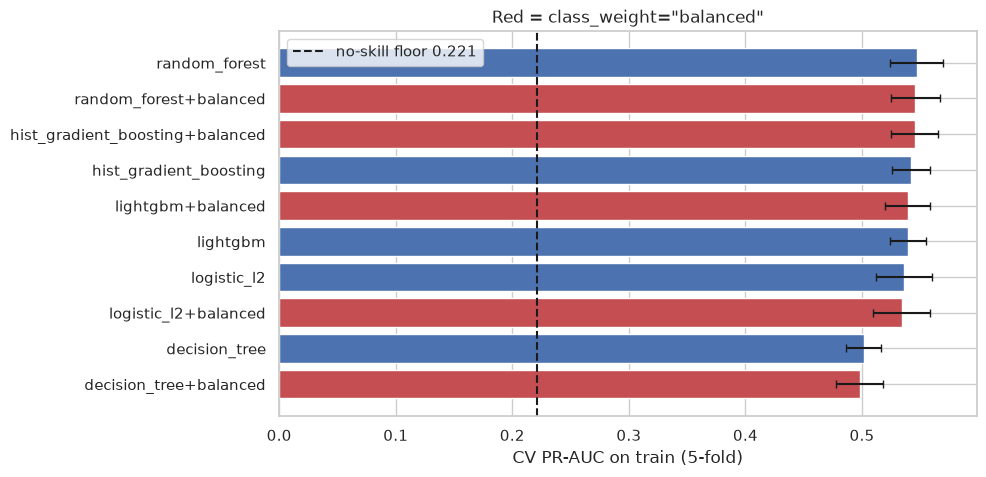

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
d = comp.sort_values('cv_pr_auc')
ax.barh(d.model, d.cv_pr_auc, xerr=d.cv_pr_sd, capsize=3,
        color=['#c44e52' if w != 'none' else '#4c72b0' for w in d.class_weight])
ax.axvline(base, color='k', ls='--', label=f'no-skill floor {base:.3f}')
ax.set_xlabel('CV PR-AUC on train (5-fold)'); ax.legend()
ax.set_title('Red = class_weight="balanced"')
plt.show()

### The class-imbalance result

The problem statement asks for imbalance to be handled — SMOTE, class weights, or
downsampling. Class weighting was tested as the cheapest of the three.

It does not improve the ranking. It does wreck the probabilities, and the Brier column is
where that shows up. Re-weighting the loss makes the model behave as if defaults were far
more common than they are, so the probabilities come out inflated. The ordering barely moves,
which is why PR-AUC and ROC-AUC do not notice.

In [5]:
pairs = comp.assign(family=comp.model.str.replace(r'\+balanced$', '', regex=True))
piv = pairs.pivot_table(index='family', columns='class_weight',
                        values=['cv_pr_auc', 'val_pr_auc', 'brier', 'recall', 'precision'])
display(piv.round(4))

delta = piv['brier']['balanced'] - piv['brier']['none']
print('change in Brier when class weighting is turned on (lower is better):')
print(delta.round(4).to_string())
print(f"\nit is worse for {int((delta > 0).sum())} of {len(delta)} families")
d_pr = piv['val_pr_auc']['balanced'] - piv['val_pr_auc']['none']
print(f"change in validation PR-AUC: {d_pr.round(4).to_dict()}")

brier         cv_pr_auc         precision           recall         val_pr_auc        
class_weight           balanced    none  balanced    none  balanced    none balanced    none   balanced    none
family                                                                                                         
decision_tree            0.1820  0.1361    0.4980  0.5013    0.4587  0.6910   0.6453  0.3426     0.5236  0.5164
hist_gradient_boosting   0.1736  0.1312    0.5451  0.5418    0.4869  0.6788   0.6332  0.3796     0.5727  0.5782
lightgbm                 0.1639  0.1321    0.5393  0.5391    0.4921  0.6816   0.6143  0.3894     0.5719  0.5707
logistic_l2              0.1812  0.1344    0.5340  0.5361    0.5148  0.6808   0.5909  0.3638     0.5538  0.5549
random_forest            0.1602  0.1322    0.5456  0.5471    0.5298  0.6824   0.5842  0.3600     0.5728  0.5742

change in Brier when class weighting is turned on (lower is better):
family
decision_tree             0.0459
hist_gradient_boosting    0.0424
lightgbm                  0.0318
logistic_l2               0.0468
random_forest             0.0280

it is worse for 5 of 5 families
change in validation PR-AUC: {'decision_tree': 0.0072, 'hist_gradient_boosting': -0.0055, 'lightgbm': 0.0012, 'logistic_l2': -0.001, 'random_forest': -0.0014}


Weighting does raise recall at a 0.5 cutoff — but that is just the cutoff moving, and
notebook 04 moves the cutoff deliberately instead. Giving up sensible probabilities for
something the threshold can do anyway is a bad trade.

**Kept: the unweighted model.**

## The encoding ablation

The one feature-engineering change that paid. Same model (logistic regression), same split,
same seed. The change targets `PAY_*`, but arm B also one-hot encodes `EDUCATION`,
`MARRIAGE` and `SEX`, so the gain belongs to the categorical encoding as a whole.

- **A**: hand the raw frame to a scaler, so the codes go in as integers `-2 … 8`. This assumes
  they are ordered by risk.
- **B**: collapse them to categories and one-hot encode them first.

In [6]:
display(abl.round(4))
gain = abl.roc_auc_gain_vs_A.dropna().iloc[0]
a, b = abl.roc_auc.iloc[0], abl.roc_auc.iloc[1]
print(f"ROC-AUC {a:.4f} -> {b:.4f}, a gain of {gain:+.4f}")
print(f"PR-AUC  {abl.pr_auc.iloc[0]:.4f} -> {abl.pr_auc.iloc[1]:.4f}")
print('no new features, no tuning, no extra model -- one encoding decision')

,model,roc_auc,pr_auc,pr_auc_no_skill,brier,accuracy,precision,recall,specificity,f1,flagged_rate,lift,threshold,roc_auc_gain_vs_A
0,A: PAY_* as integers (ordinal assumption),0.7305,0.5107,0.2212,0.1439,0.8110,0.7218,0.2370,0.9741,0.3568,0.0726,3.2627,0.5,NaN
1,B: PAY_* as collapsed categories,0.7770,0.5549,0.2212,0.1344,0.8215,0.6808,0.3638,0.9515,0.4742,0.1182,3.0772,0.5,0.0464


ROC-AUC 0.7305 -> 0.7770, a gain of +0.0464
PR-AUC  0.5107 -> 0.5549
no new features, no tuning, no extra model -- one encoding decision


For scale: every model above lands within a few hundredths of ROC-AUC of every other (see
the spread line), so for logistic regression the encoding mattered about as much as the
choice of algorithm. It was not re-measured on the tree models.

## Tuning

30 random draws over the HistGradientBoosting hyperparameters, scored on CV PR-AUC.

In [7]:
print(json.dumps(tuning['params'], indent=2))
print(f"CV PR-AUC   {tuning['cv_pr_auc_untuned']:.4f} -> {tuning['cv_pr_auc']:.4f} "
      f"({tuning['cv_pr_auc'] - tuning['cv_pr_auc_untuned']:+.4f})")
print(f"validation  {tuning['val_pr_auc_untuned']:.4f} -> {tuning['val_pr_auc']:.4f} "
      f"({tuning['val_pr_auc'] - tuning['val_pr_auc_untuned']:+.4f})")

{
  "l2_regularization": 0.02715581955282941,
  "learning_rate": 0.014830392684568025,
  "max_iter": 234,
  "max_leaf_nodes": 16,
  "min_samples_leaf": 81
}
CV PR-AUC   0.5418 -> 0.5488 (+0.0070)
validation  0.5782 -> 0.5769 (-0.0013)


Tuning bought a small gain on the CV score it was optimising and nothing on validation. That
is the honest reading: the untuned defaults were already close to the ceiling for this feature
set, and the search mostly fitted the folds. The tuned configuration is carried forward
because it is the one that was selected, not because it is better.

## Selection

**HistGradientBoosting, unweighted, tuned.** It leads on validation PR-AUC, ties on CV with
the random forest, and is a sklearn built-in — LightGBM scores slightly below it here, so the
extra dependency buys nothing. The decision tree is several points behind, which is the price
of a model you can draw on one page.